姓名：李晨辉　　学号：2026009793　　日期：2026-11-11

# 01｜MLP 基线：Fashion-MNIST 图像分类

## 学习目标
- 理解图像张量、标签和分类输出；
- 理解交叉熵、反向传播与优化器的基本作用；
- 观察训练集与验证集指标；
- 修改一个训练设置，并用数据解释变化。

**实验纪律：** 本 Notebook 使用训练集与验证集。测试集只在全部实验设置冻结后，由最终评估 Notebook 统一使用。

## 1. 导入库、固定随机种子并加载数据
运行以下单元格。首次运行会下载 Fashion-MNIST。

In [1]:
from pathlib import Path
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

SEED = 42
BATCH_SIZE = 128
EPOCHS = 5
LEARNING_RATE = 1e-3
NUM_WORKERS = 0  # 对初学者和 Windows 环境更稳妥
DATA_DIR = Path("data")
RESULTS_DIR = Path("results")
DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

transform = transforms.ToTensor()
full_train_dataset = datasets.FashionMNIST(
    root=str(DATA_DIR), train=True, download=True, transform=transform
)
test_dataset = datasets.FashionMNIST(
    root=str(DATA_DIR), train=False, download=True, transform=transform
)
train_dataset, val_dataset = random_split(
    full_train_dataset,
    [55000, 5000],
    generator=torch.Generator().manual_seed(SEED)
)

def make_loaders(seed=SEED):
    generator = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(
        train_dataset, batch_size=BATCH_SIZE, shuffle=True,
        num_workers=NUM_WORKERS, generator=generator
    )
    val_loader = DataLoader(
        val_dataset, batch_size=BATCH_SIZE, shuffle=False,
        num_workers=NUM_WORKERS
    )
    return train_loader, val_loader

train_loader, val_loader = make_loaders()
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS
)

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]
print(f"训练集: {len(train_dataset)} | 验证集: {len(val_dataset)} | 测试集: {len(test_dataset)}")
print("注意：本 Notebook 只使用训练集和验证集进行开发；测试集留到最终验收时再使用。")


Device: cpu
训练集: 55000 | 验证集: 5000 | 测试集: 10000
注意：本 Notebook 只使用训练集和验证集进行开发；测试集留到最终验收时再使用。


## 2. 查看一批数据

请观察图像尺寸、标签编号和对应的服饰类别。

Batch image shape: (128, 1, 28, 28)
Batch label shape: (128,)
First 10 labels: [0, 6, 7, 6, 1, 3, 2, 6, 4, 1]


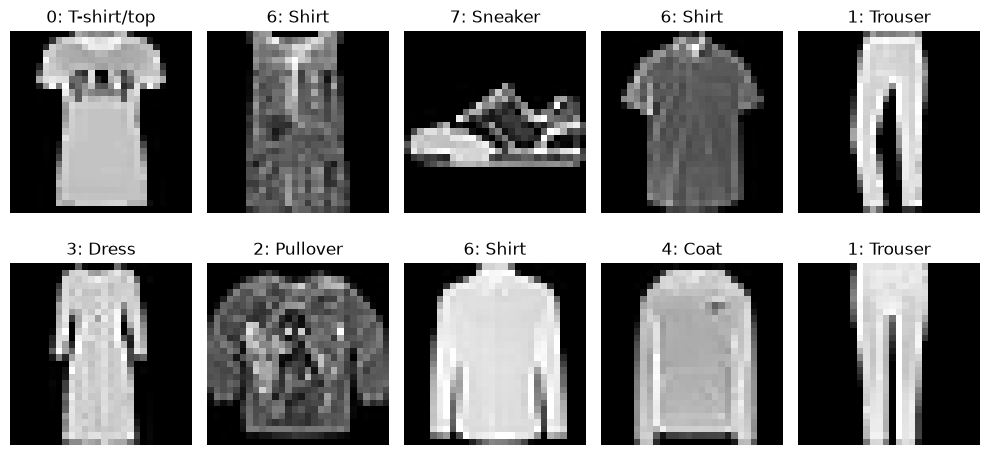

In [2]:
images, labels = next(iter(train_loader))
print("Batch image shape:", tuple(images.shape))  # 预期形状类似 [batch, 1, 28, 28]
print("Batch label shape:", tuple(labels.shape))
print("First 10 labels:", labels[:10].tolist())

fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for ax, image, label in zip(axes.flat, images[:10], labels[:10]):
    ax.imshow(image.squeeze(0), cmap="gray")
    ax.set_title(f"{label.item()}: {class_names[label.item()]}")
    ax.axis("off")
plt.tight_layout()
plt.show()


## 3. 定义 MLP 基线

MLP（多层感知机）会先把每张 `1×28×28` 图像展平为 784 维向量，再通过全连接层输出 10 个类别的 logits。这里不在模型末尾手动添加 Softmax，因为 `CrossEntropyLoss` 接收 logits 并在内部处理相应的数值计算。

In [3]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.network(x)

mlp = MLP()
print(mlp)
sample_logits = mlp(images[:4])
print("输出形状:", tuple(sample_logits.shape), "（4 张图片，每张对应 10 个类别分数）")


MLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
输出形状: (4, 10) （4 张图片，每张对应 10 个类别分数）


## 4. 训练与验证

先运行基线。请不要只看最后一个准确率数值；还要观察损失和验证指标随 epoch 的变化。

In [4]:
def run_epoch(model, loader, criterion, optimizer=None):
    is_training = optimizer is not None
    model.train() if is_training else model.eval()
    total_loss, total_correct, total_count = 0.0, 0, 0

    with torch.set_grad_enabled(is_training):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            if is_training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(images)
            loss = criterion(logits, labels)

            if is_training:
                loss.backward()
                optimizer.step()

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            total_correct += (logits.argmax(dim=1) == labels).sum().item()
            total_count += batch_size

    return total_loss / total_count, 100.0 * total_correct / total_count


def fit_model(model, train_loader, val_loader, epochs, learning_rate, run_name):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history = []

    for epoch in range(1, epochs + 1):
        train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc = run_epoch(model, val_loader, criterion)
        row = {
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy_pct": train_acc,
            "val_loss": val_loss,
            "val_accuracy_pct": val_acc,
            "learning_rate": learning_rate,
        }
        history.append(row)
        print(
            f"[{run_name}] Epoch {epoch:02d}/{epochs} | "
            f"train loss={train_loss:.4f}, train acc={train_acc:.2f}% | "
            f"val loss={val_loss:.4f}, val acc={val_acc:.2f}%"
        )

    history_df = pd.DataFrame(history)
    history_df.to_csv(RESULTS_DIR / f"{run_name}_history.csv", index=False)
    metrics = {
        "run_name": run_name,
        "seed": SEED,
        "epochs": epochs,
        "learning_rate": learning_rate,
        "final_train_loss": float(history_df.iloc[-1]["train_loss"]),
        "final_train_accuracy_pct": float(history_df.iloc[-1]["train_accuracy_pct"]),
        "final_val_loss": float(history_df.iloc[-1]["val_loss"]),
        "final_val_accuracy_pct": float(history_df.iloc[-1]["val_accuracy_pct"]),
        "best_val_accuracy_pct": float(history_df["val_accuracy_pct"].max()),
        "device": str(device),
    }
    (RESULTS_DIR / f"{run_name}_metrics.json").write_text(
        json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    torch.save(model.state_dict(), RESULTS_DIR / f"{run_name}_state_dict.pt")
    return model, history_df, metrics


def plot_history(history_df, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Train")
    axes[0].plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()
    axes[1].plot(history_df["epoch"], history_df["train_accuracy_pct"], marker="o", label="Train")
    axes[1].plot(history_df["epoch"], history_df["val_accuracy_pct"], marker="o", label="Validation")
    axes[1].set_title("Accuracy (%)")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / f"{title.lower().replace(' ', '_')}_curves.png", dpi=150)
    plt.show()


[mlp_baseline] Epoch 01/5 | train loss=0.5802, train acc=79.53% | val loss=0.4479, val acc=84.20%


[mlp_baseline] Epoch 02/5 | train loss=0.3940, train acc=85.79% | val loss=0.4065, val acc=85.28%


[mlp_baseline] Epoch 03/5 | train loss=0.3516, train acc=87.22% | val loss=0.3874, val acc=85.84%


[mlp_baseline] Epoch 04/5 | train loss=0.3227, train acc=88.23% | val loss=0.3632, val acc=87.12%


[mlp_baseline] Epoch 05/5 | train loss=0.3058, train acc=88.76% | val loss=0.3680, val acc=86.26%


,epoch,train_loss,train_accuracy_pct,val_loss,val_accuracy_pct,learning_rate
0,1,0.580205,79.534545,0.447893,84.20,0.001
1,2,0.393977,85.787273,0.406472,85.28,0.001
2,3,0.351592,87.221818,0.387415,85.84,0.001
3,4,0.322720,88.229091,0.363219,87.12,0.001
4,5,0.305820,88.758182,0.367969,86.26,0.001


{
  "run_name": "mlp_baseline",
  "seed": 42,
  "epochs": 5,
  "learning_rate": 0.001,
  "final_train_loss": 0.3058198554212397,
  "final_train_accuracy_pct": 88.75818181818182,
  "final_val_loss": 0.3679688751220703,
  "final_val_accuracy_pct": 86.26,
  "best_val_accuracy_pct": 87.12,
  "device": "cpu"
}


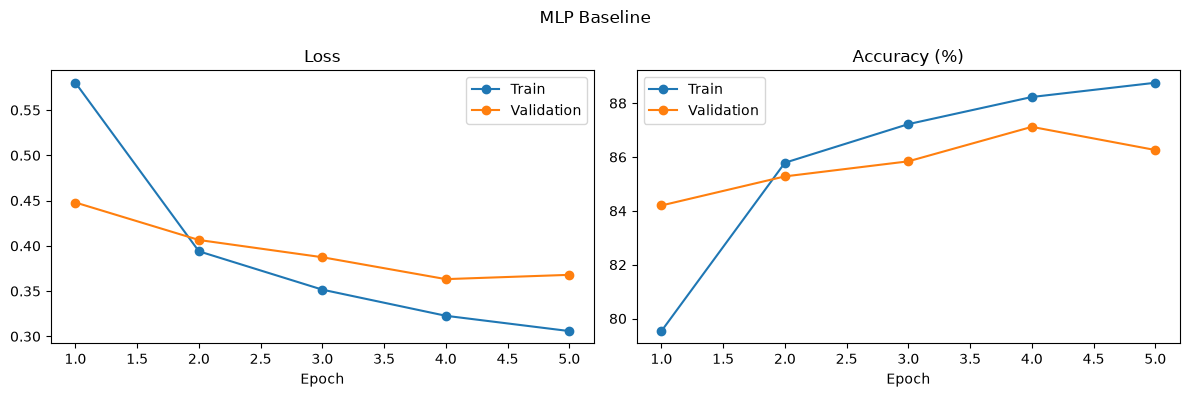

In [5]:
mlp, mlp_history, mlp_metrics = fit_model(
    model=MLP(),
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
    run_name="mlp_baseline"
)
display(mlp_history)
print(json.dumps(mlp_metrics, ensure_ascii=False, indent=2))
plot_history(mlp_history, "MLP Baseline")


## 6. 独立修改：学习率从 1e-3 改成 3e-4

基线结果保留不动，修改后的这次另存为 `mlp_lr_variant_0p0003`。
只改学习率这一个变量，模型结构、数据划分、batch size、训练轮数、优化器和随机种子都不变。

[mlp_lr_variant_0p0003] Epoch 01/5 | train loss=0.7207, train acc=75.81% | val loss=0.5092, val acc=82.20%


[mlp_lr_variant_0p0003] Epoch 02/5 | train loss=0.4530, train acc=84.14% | val loss=0.4356, val acc=84.28%


[mlp_lr_variant_0p0003] Epoch 03/5 | train loss=0.4054, train acc=85.73% | val loss=0.4323, val acc=84.70%


[mlp_lr_variant_0p0003] Epoch 04/5 | train loss=0.3772, train acc=86.69% | val loss=0.4029, val acc=86.30%


[mlp_lr_variant_0p0003] Epoch 05/5 | train loss=0.3589, train acc=87.19% | val loss=0.3809, val acc=86.82%


,epoch,train_loss,train_accuracy_pct,val_loss,val_accuracy_pct,learning_rate
0,1,0.720706,75.809091,0.509171,82.20,0.0003
1,2,0.453002,84.138182,0.435638,84.28,0.0003
2,3,0.405392,85.725455,0.432281,84.70,0.0003
3,4,0.377190,86.692727,0.402895,86.30,0.0003
4,5,0.358935,87.190909,0.380858,86.82,0.0003


{
  "run_name": "mlp_lr_variant_0p0003",
  "seed": 42,
  "epochs": 5,
  "learning_rate": 0.0003,
  "final_train_loss": 0.3589349336017262,
  "final_train_accuracy_pct": 87.19090909090909,
  "final_val_loss": 0.3808580984830856,
  "final_val_accuracy_pct": 86.82,
  "best_val_accuracy_pct": 86.82,
  "device": "cpu"
}


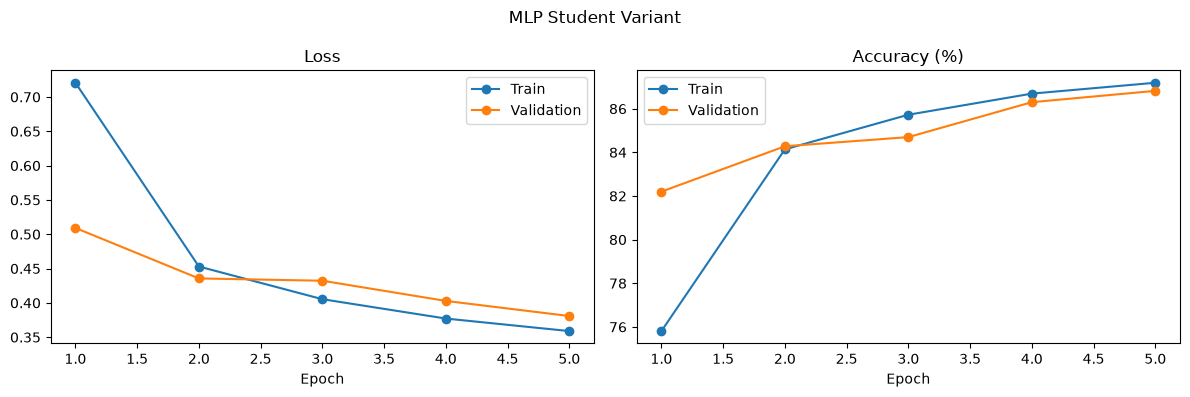

In [6]:
# 学生修改：把学习率从基线的 1e-3 降到 3e-4，其余设置保持不变
# 选择理由见下方“修改说明”单元格；结果以 mlp_lr_variant_0p0003 独立保存，不覆盖基线。
STUDENT_LEARNING_RATE = 3e-4

mlp_variant, mlp_variant_history, mlp_variant_metrics = fit_model(
    model=MLP(),
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS,
    learning_rate=STUDENT_LEARNING_RATE,
    run_name=f"mlp_lr_variant_{str(STUDENT_LEARNING_RATE).replace('.', 'p')}"
)
display(mlp_variant_history)
print(json.dumps(mlp_variant_metrics, ensure_ascii=False, indent=2))
plot_history(mlp_variant_history, "MLP Student Variant")

### 修改说明

这次只动了一个变量：学习率从 `1e-3` 改成 `3e-4`，模型结构、数据划分、batch size、训练轮数、优化器（Adam）和随机种子都没变。

选它的原因：基线 5 轮跑下来训练损失一直在降，但验证损失第 5 轮反而比第 4 轮高了一点（0.3632→0.3680），验证准确率也回落了，我猜是 1e-3 到后期步长偏大。把学习率调小，参数更新会稳一些，代价是同样的 5 轮里收敛得更慢。

预期：验证曲线更平滑、末轮验证损失更低或差不多，但训练/验证准确率会比基线低一点。

实际跑出来：

- 基线 `mlp_baseline`（lr=1e-3）：训练损失 0.3058 / 准确率 88.76%，验证损失 0.3680 / 准确率 86.26%（5 轮最好 87.12%）
- 变体 `mlp_lr_variant_0p0003`（lr=3e-4）：训练损失 0.3589 / 准确率 87.19%，验证损失 0.3809 / 准确率 86.82%（5 轮最好 86.82%）
- 对比：验证准确率 +0.56 个百分点，训练准确率 −1.57 个百分点

训练准确率掉了、验证准确率反而略高，和“步长小、5 轮没拟合够”对得上；变体的验证曲线确实是单调往上走的，没有基线那种末期回落。不过只跑了一个种子，0.56 个百分点说明不了太多，只能说这次预算下两者差不多、3e-4 更稳一点。


## 5. 修改小结与思考题

调整后的结果是验证准确率 86.82%、训练准确率 87.19%，和基线相比一个略高一个略低，具体差别和原因写在上面的修改说明里。

## 思考题
1. 为什么分类模型输出 10 个 logits，而不是直接输出一个类别编号？
2. `loss.backward()` 和 `optimizer.step()` 分别做什么？
3. 如果训练准确率持续上升而验证准确率停滞，可能意味着什么？
4. 为什么不能只用训练集评估模型？